In [79]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score
import xgboost as xgb

In [81]:
train = pd.read_csv('cs-training.csv')
train.drop('Unnamed: 0', axis=1, inplace=True)

In [82]:
train.head(5)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


<Axes: >

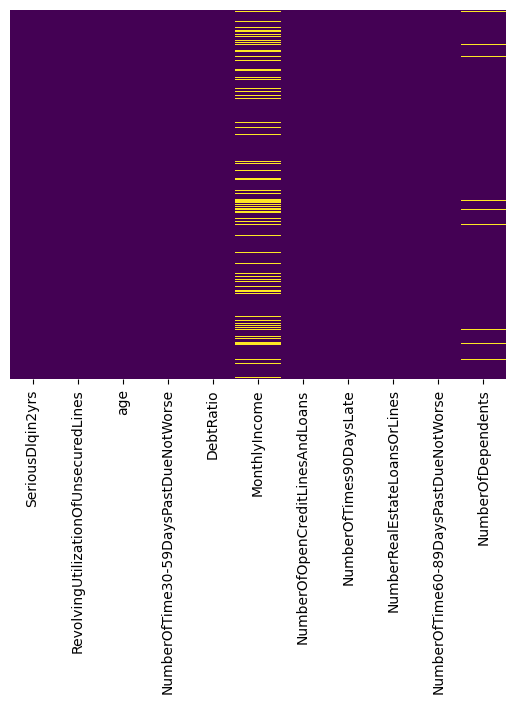

In [57]:
sns.heatmap(train.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [83]:
train['NumberOfDependents'] = train['NumberOfDependents'].fillna(0)

In [84]:
a_0 = train[train['SeriousDlqin2yrs']==0]['SeriousDlqin2yrs'].value_counts().sum()
a_1 = train[train['SeriousDlqin2yrs']==1]['SeriousDlqin2yrs'].value_counts().sum()
disbalance_ratio = round(a_0/a_1, 2)
print('1:', a_1)
print('0:', a_0)
print('class disbalance ratio:', disbalance_ratio)

1: 10026
0: 139974
class disbalance ratio: 13.96


In [85]:
print('age min:', train['age'].min())
print('age median:', train['age'].median())
print('age max:', train['age'].max())
print('amount age < 18:', train[train['age']<18]['age'].value_counts().sum())
print('amount age > 100:', train[train['age']>100]['age'].value_counts().sum())

age min: 0
age median: 52.0
age max: 109
amount age < 18: 1
amount age > 100: 13


In [86]:
train = train[train['age']!=0].copy()

In [87]:
bins = [17, 21, 25, 35, 50, 65, 110]
train['age_group'] = pd.cut(train['age'], bins=bins, labels=['21_or_less', '22-25', '26-35', '36-50', '51-65', '65_plus'])

In [88]:
y = train['SeriousDlqin2yrs']
train.drop('SeriousDlqin2yrs', axis=1, inplace=True)

In [144]:
test = pd.read_csv('cs-test.csv')

test.drop('Unnamed: 0', axis=1, inplace=True)
test['NumberOfDependents'] = test['NumberOfDependents'].fillna(0)
test['age_group'] = pd.cut(test['age'], bins=bins, labels=['21_or_less', '22-25', '26-35', '36-50', '51-65', '65_plus'])
test.drop('SeriousDlqin2yrs', axis=1, inplace=True)

In [145]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

auc_scores = []
oof_preds = np.zeros(len(train))
test_preds_total = np.zeros(len(test))

In [146]:
print('Результаты кросс-валидации:')
for fold, (train_idx, val_idx) in enumerate(cv.split(train, y)):
    X_train, y_train = train.iloc[train_idx].copy(), y.iloc[train_idx]
    X_val, y_val = train.iloc[val_idx].copy(), y.iloc[val_idx]
    X_test = test.copy()

    group_medians_income = X_train.groupby('age_group', observed=False)['MonthlyIncome'].median()
    global_median_income = X_train['MonthlyIncome'].median()
    medians_dict_income = group_medians_income.to_dict()

    group_medians_ratio = X_train.groupby('age_group', observed=False)['DebtRatio'].median()
    global_median_ratio = X_train['DebtRatio'].median()
    medians_dict_ratio = group_medians_ratio.to_dict()

    train_mapped_income = X_train['age_group'].map(medians_dict_income).to_numpy()
    X_train['MonthlyIncome'] = np.where(X_train['MonthlyIncome'].isna(), train_mapped_income, X_train['MonthlyIncome'])
    X_train['MonthlyIncome'] = np.where(X_train['MonthlyIncome'].isna(), global_median_income, X_train['MonthlyIncome'])

    train_mapped_ratio = X_train['age_group'].map(medians_dict_ratio).to_numpy()
    X_train['DebtRatio'] = np.where(X_train['DebtRatio']>1, train_mapped_ratio, X_train['DebtRatio'])
    X_train['DebtRatio'] = np.where(X_train['DebtRatio']>1, global_median_ratio, X_train['DebtRatio'])

    val_mapped_income = X_val['age_group'].map(medians_dict_income).to_numpy()
    X_val['MonthlyIncome'] = np.where(X_val['MonthlyIncome'].isna(), val_mapped_income, X_val['MonthlyIncome'])
    X_val['MonthlyIncome'] = np.where(X_val['MonthlyIncome'].isna(), global_median_income, X_val['MonthlyIncome'])

    val_mapped_ratio = X_val['age_group'].map(medians_dict_ratio).to_numpy()
    X_val['DebtRatio'] = np.where(X_val['DebtRatio']>1, val_mapped_ratio, X_val['DebtRatio'])
    X_val['DebtRatio'] = np.where(X_val['DebtRatio']>1, global_median_ratio, X_val['DebtRatio'])

    test_mapped_income = test['age_group'].map(medians_dict_income).to_numpy()
    X_test['MonthlyIncome'] = np.where(X_test['MonthlyIncome'].isna(), test_mapped_income, X_test['MonthlyIncome'])
    X_test['MonthlyIncome'] = np.where(X_test['MonthlyIncome'].isna(), global_median_income, X_test['MonthlyIncome'])

    test_mapped_ratio = test['age_group'].map(medians_dict_ratio).to_numpy()
    X_test['DebtRatio'] = np.where(X_test['DebtRatio']>1, test_mapped_ratio, X_test['DebtRatio'])
    X_test['DebtRatio'] = np.where(X_test['DebtRatio']>1, global_median_ratio, X_test['DebtRatio'])

    model = xgb.XGBClassifier(scale_pos_weight=disbalance_ratio,
                              eval_metric='auc',
                              random_state=42,
                              n_estimators=1500,
                              learning_rate=0.05,
                              max_depth=4,
                              early_stopping_rounds=50,
                              enable_categorical=True)

    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)],
              verbose=False)

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    test_preds_total += model.predict_proba(X_test)[:, 1] / cv.n_splits

    fold_auc = roc_auc_score(y_val, val_preds)
    auc_scores.append(fold_auc)
    print('Fold', fold+1, 'AUC:', round(fold_auc,4))

Результаты кросс-валидации:
Fold 1 AUC: 0.8635
Fold 2 AUC: 0.866
Fold 3 AUC: 0.8671
Fold 4 AUC: 0.8579
Fold 5 AUC: 0.8695


In [147]:
submission = pd.DataFrame({
    'Id': test.index+1,
    'Probability': test_preds_total})

submission.to_csv('submission_xgb_credit.csv', index=False)